# Assignment 2 – Steady-state: single-storey two-zone office building (Chur)

**Team:** _Valerio Paganini_

Intermediate submission, *dm4bem* (Ch. Ghiaus). Thermal circuit of Assignment 1
([Assignment1_Model.ipynb](Assignment1_Model.ipynb), Figure 1): 155 nodes, 191 branches, two zones (south and
north half) coupled by an interior wall and a closed door.

1. DAE matrices $A$, $G$, $C$
2. inputs $b$, $f$
3. steady state of the DAE
4. state-space matrices $A_s$, $B_s$, $C_s$, $D_s$
5. input vector $u = [b_T^T, f_Q^T]^T$
6. steady state of the state-space model
7. comparison
8. visual check of the matrices (addition)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dm4bem
from IPython.utils import io

## 1 Matrices $A$, $G$ and $C$ of the DAE

Assignment 1 is run silently. It defines the incidence matrix `A` (191 × 155), the diagonal matrices `G`
(191 × 191, W/K) and `C` (155 × 155, J/K), the pointer vectors `b`, `f`, `y` and the list `branches`
(from node, to node, conductance, temperature source).

In [2]:
with io.capture_output():                   # model of Assignment 1, its outputs are not shown
    %run Assignment1_Model.ipynb

b_ptr, f_ptr, y_ptr = b.copy(), f.copy(), y.copy()     # pointers: 1 = temperature source / flow source / output
src = pd.Series({k: s for k, (_, _, _, s) in enumerate(branches) if s})   # source of every branch with b = 1
k_ctrl = list(src.index[src.str.startswith('T_sp')])                      # P-controllers: q88, q177

print(f'A {A.shape}, G {G.shape}, C {C.shape}')
print(f'{int(b_ptr.sum())} temperature sources, {int(f_ptr.sum())} flow-rate sources, outputs θ{air1}, θ{air2}')
print(f'P-controllers on branches {[f"q{k}" for k in k_ctrl]}')

A (191, 155), G (191, 191), C (155, 155)
20 temperature sources, 28 flow-rate sources, outputs θ71, θ144
P-controllers on branches ['q88', 'q177']


## 2 Inputs: temperature sources $b$ and flow-rate sources $f$

*Case 1, model test* (as in 03CubicBuilding): $K_p = 0$, $T_o = T_{bsmt} = 10$ °C, $T_{sp} = 20$ °C (no effect),
no flow-rate sources. All nodes must reach 10 °C; this can falsify the model but not prove it.

*Case 2, design heating load*: $T_o = -7.2$ °C, SIA design value for Chur (assumption);
$T_{bsmt} = 20 - 0.7\,(20 - T_o) = 0.96$ °C (hypothesis 5, $T_{o,24h} = T_o$); $T_{sp} = 21$ °C in both zones;
$K_p = 10^5$ W/K; no sun, no internal gains.

*Case 3, zone 2 set-back*: case 2 plus full-load gains in zone 1 (hypothesis 9; SIA 2024 room type 3.01,
assumption): 84 W per person at 14 m² per person, equipment 11 W/m², lighting 9.72 W/m², 6.0 kW in total on
$\theta_{71}$. Zone 2 unoccupied, $T_{sp,2} = 18$ °C (hypothesis 12).

$b$ is in °C per branch, $f$ in W per node.

In [3]:
def inputs(T_o, T_bsmt, T_sp, Q=None):
    """Values of the temperature sources b (°C) and of the flow-rate sources f (W).

    T_sp: one set-point for both zones or a pair (zone 1, zone 2); Q: {node: flow rate in W}."""
    T_sp1, T_sp2 = (T_sp, T_sp) if np.isscalar(T_sp) else T_sp
    value = {'T_o': T_o, 'T_bsmt': T_bsmt, 'T_sp,1': T_sp1, 'T_sp,2': T_sp2}
    b = np.zeros(nq)
    for k, s in src.items():
        b[k] = value[s]
    f = np.zeros(nθ)
    for node, Q_node in (Q or {}).items():
        f[node] = Q_node
    return b, f


def conductances(K_p):
    """Conductance matrix G of Assignment 1 with the gain K_p (W/K) on the controller branches."""
    G_K = G.copy()
    G_K[k_ctrl, k_ctrl] = K_p
    return G_K


T_o2 = -7.2                                 # °C, design outdoor temperature (cases 2 and 3)
T_bsmt2 = 20 - 0.7 * (20 - T_o2)            # °C, basement (hypothesis 5)
Q_occ = S_plan / 14 * 84                    # W, occupants: 14 m²/P, 84 W/P (full load, case 3)
Q_equip = S_plan * 11                       # W, equipment 11 W/m²
Q_light = S_plan * 9.72                     # W, lighting 9.72 W/m²
cases = {
    'case 1: test': dict(G=conductances(0), inputs=inputs(T_o=10, T_bsmt=10, T_sp=20)),
    'case 2: design heating': dict(G=conductances(1e5), inputs=inputs(T_o=T_o2, T_bsmt=T_bsmt2, T_sp=21)),
    'case 3: zone 2 set-back': dict(G=conductances(1e5),
                                    inputs=inputs(T_o=T_o2, T_bsmt=T_bsmt2, T_sp=(21, 18),
                                                  Q={air1: Q_occ + Q_equip + Q_light})),
}
pd.DataFrame({name: {**{f'{s} (°C)': c['inputs'][0][src.index[src == s][0]] for s in src.unique()},
                     'K_p (W/K)': c['G'][k_ctrl[0], k_ctrl[0]],
                     'sum of the flow-rate sources (W)': c['inputs'][1].sum()}
              for name, c in cases.items()})

,case 1: test,case 2: design heating,case 3: zone 2 set-back
T_o (°C),10.0,-7.20,-7.20
T_bsmt (°C),10.0,0.96,0.96
"T_sp,1 (°C)",20.0,21.00,21.00
"T_sp,2 (°C)",20.0,21.00,18.00
K_p (W/K),0.0,100000.00,100000.00
sum of the flow-rate sources (W),0.0,0.00,6012.00


## 3 Steady-state response of the DAE

In steady state $C \dot\theta = 0$, so

$$\theta_{ss} = (A^T G A)^{-1}(A^T G b + f), \qquad q_{ss} = G(-A\theta_{ss} + b)$$

In [4]:
for name, c in cases.items():
    Gc = c['G']
    b_v, f_v = c['inputs']
    c['θ'] = np.linalg.inv(A.T @ Gc @ A) @ (A.T @ Gc @ b_v + f_v)
    c['q'] = Gc @ (-A @ c['θ'] + b_v)
    θ = c['θ']
    print(f'{name}: θ min / max = {θ.min():.4f} / {θ.max():.4f} °C, '
          f'air θ{air1} = {θ[air1]:.4f} °C, θ{air2} = {θ[air2]:.4f} °C')

case 1: test: θ min / max = 10.0000 / 10.0000 °C, air θ71 = 10.0000 °C, θ144 = 10.0000 °C


case 2: design heating: θ min / max = -7.0397 / 20.9447 °C, air θ71 = 20.9447 °C, θ144 = 20.9447 °C
case 3: zone 2 set-back: θ min / max = -7.0556 / 20.9991 °C, air θ71 = 20.9991 °C, θ144 = 17.9564 °C


Case 1 gives 10.00 °C in every node, so the model passes the test.

Case 2, south wall of zone 1 (nodes $\theta_0 \dots \theta_{12}$): almost the whole temperature drop is in the
insulation.

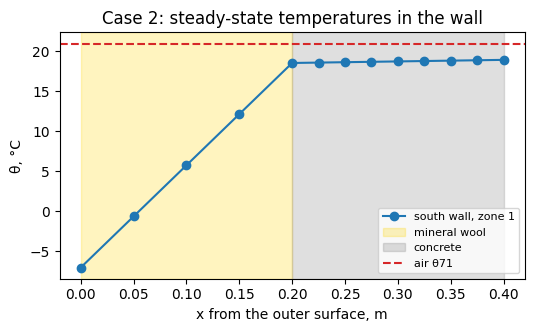

In [5]:
(m1, w1), (m2, w2) = wall                                          # layers of the external wall (Assignment 1)
x = np.r_[np.arange(5) * w1 / 4, w1 + np.arange(1, 9) * w2 / 8]    # m, position of θ0 … θ12 from the outside
θ = cases['case 2: design heating']['θ']
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(x, θ[:13], 'o-', label='south wall, zone 1')
ax.axvspan(0, w1, color='gold', alpha=0.25, label=m1.replace('_', ' '))
ax.axvspan(w1, w1 + w2, color='grey', alpha=0.25, label=m2)
ax.axhline(θ[air1], color='tab:red', ls='--', label=f'air θ{air1}')
ax.set(xlabel='x from the outer surface, m', ylabel='θ, °C', title='Case 2: steady-state temperatures in the wall')
ax.legend(fontsize=8)
plt.show()

Heat losses, case 2. The flow in a temperature-source branch is the heat from the source into the building,
so $-q$ is the loss through the element. Without gains, the losses sum to the heat of the two P-controllers.

In [6]:
q = cases['case 2: design heating']['q']
elements = {'wall S/N': 0, 'window S/N': 15, 'wall E': 19, 'window E': 34, 'wall W': 38, 'window W': 53,
            'roof': 57, 'floor (basement)': 72, 'ventilation': 87}
loss = pd.DataFrame({'zone 1 (W)': {e: -q[k] for e, k in elements.items()},
                     'zone 2 (W)': {e: -q[k + 89] for e, k in elements.items()}})
loss.loc['sum of the losses'] = loss.sum()
loss.loc['heating load q_HVAC'] = [q[k_ctrl[0]], q[k_ctrl[1]]]
loss['total (W)'] = loss.sum(axis=1)
share = loss.loc[list(elements), 'total (W)'] / loss.loc['sum of the losses', 'total (W)']
print(f'heating load {q[k_ctrl[0]] / 1000:.2f} kW per zone = {q[k_ctrl[0]] / S_plan:.1f} W/m² of floor; '
      f'air {cases["case 2: design heating"]["θ"][air1]:.2f} °C (set-point 21 °C)')
print(f'shares: windows {share.filter(like="window").sum():.0%}, ventilation {share["ventilation"]:.0%}, '
      f'roof {share["roof"]:.0%}, floor {share["floor (basement)"]:.0%}, walls {share.filter(like="wall").sum():.0%}')
print(f'between the zones: conduction through the interior wall (q179–q186) max |q| = '
      f'{np.abs(q[179:187]).max():.1e} W, door q190 = {abs(q[190]):.1e} W')
θ = cases['case 2: design heating']['θ']
print(f'long-wave star node θ{rm1} = {θ[rm1]:.2f} °C, operative temperature ≈ (θ{air1} + θ{rm1}) / 2 = '
      f'{(θ[air1] + θ[rm1]) / 2:.2f} °C')
loss.round(0)

heating load 5.53 kW per zone = 24.6 W/m² of floor; air 20.94 °C (set-point 21 °C)
shares: windows 40%, ventilation 25%, roof 16%, floor 13%, walls 5%
between the zones: conduction through the interior wall (q179–q186) max |q| = 2.3e-11 W, door q190 = 0.0e+00 W
long-wave star node θ72 = 18.77 °C, operative temperature ≈ (θ71 + θ72) / 2 = 19.86 °C


,zone 1 (W),zone 2 (W),total (W)
wall S/N,182.0,182.0,365.0
window S/N,1468.0,1468.0,2937.0
wall E,46.0,46.0,91.0
window E,367.0,367.0,734.0
wall W,46.0,46.0,91.0
window W,367.0,367.0,734.0
roof,902.0,902.0,1803.0
floor (basement),745.0,745.0,1491.0
ventilation,1410.0,1410.0,2819.0
sum of the losses,5533.0,5533.0,11066.0


Energy balance of each zone, case 3. In steady state $q_{179} = \dots = q_{186}$ through the interior wall;
this plus the door $q_{190}$ is the heat from zone 1 to zone 2.

In [7]:
q, θ = cases['case 3: zone 2 set-back']['q'], cases['case 3: zone 2 set-back']['θ']
loss1 = -sum(q[k] for k in elements.values())           # zone 1 to outdoor and basement
loss2 = -sum(q[k + 89] for k in elements.values())      # zone 2 to outdoor and basement
q12 = q[179] + q[190]                                   # zone 1 to zone 2: interior wall + door
print(f'air θ{air1} = {θ[air1]:.2f} °C (zone 1), θ{air2} = {θ[air2]:.2f} °C (zone 2)')
print(f'zone 1: internal gains {Q_occ + Q_equip + Q_light:.0f} W + heating {q[k_ctrl[0]]:.0f} W '
      f'= losses {loss1:.0f} W + to zone 2 {q12:.0f} W')
print(f'zone 2: heating {q[k_ctrl[1]]:.0f} W + from zone 1 {q12:.0f} W = losses {loss2:.0f} W')
print(f'zone 1 to zone 2: interior wall {q[179]:.0f} W (q179 … q186), door {q[190]:.1f} W (q190)')

air θ71 = 21.00 °C (zone 1), θ144 = 17.96 °C (zone 2)
zone 1: internal gains 6012 W + heating 87 W = losses 5513 W + to zone 2 587 W
zone 2: heating 4357 W + from zone 1 587 W = losses 4944 W
zone 1 to zone 2: interior wall 575 W (q179 … q186), door 11.3 W (q190)


## 4 State-space representation

`dm4bem.tc2ss` eliminates the nodes without capacity and takes the pointers $b$, $f$, $y$, not the values. $G$
contains $K_p$, so the matrices are computed per case.

In [8]:
for name, c in cases.items():
    c['ss'] = dm4bem.tc2ss(A, c['G'], C, b_ptr, f_ptr, y_ptr)
As, Bs, Cs, Ds = cases['case 2: design heating']['ss']
print(f'As {As.shape}: {As.shape[0]} states = nodes with capacity')
print(f'Bs {Bs.shape}: {Bs.shape[1]} inputs = {int(b_ptr.sum())} temperature sources + {int(f_ptr.sum())} flow-rate sources')
print(f'Cs {Cs.shape}, Ds {Ds.shape}: {Cs.shape[0]} outputs (air temperatures)')

As (72, 72): 72 states = nodes with capacity
Bs (72, 48): 48 inputs = 20 temperature sources + 28 flow-rate sources
Cs (2, 72), Ds (2, 48): 2 outputs (air temperatures)


## 5 Input vector $u = [b_T^T, f_Q^T]^T$

$b_T$ contains $b$ on the branches with $b_k = 1$ (branch order), $f_Q$ contains $f$ on the nodes with $f_i = 1$
(node order), matching the input order of `dm4bem.tc2ss`. All flow-rate sources are zero in cases 1 and 2; in
case 3 only the internal gains on $\theta_{71}$ are non-zero.

In [9]:
u_names = [f'b: q{k} ({src[k]})' for k in np.flatnonzero(b_ptr)] + \
          [f'f: θ{i} ({"+".join(flow[i])})' for i in np.flatnonzero(f_ptr)]
for name, c in cases.items():
    b_v, f_v = c['inputs']
    c['u'] = np.hstack([b_v[b_ptr == 1], f_v[f_ptr == 1]])
pd.DataFrame({name: c['u'] for name, c in cases.items()}, index=u_names)

,case 1: test,case 2: design heating,case 3: zone 2 set-back
b: q0 (T_o),10.0,-7.20,-7.20
b: q15 (T_o),10.0,-7.20,-7.20
b: q19 (T_o),10.0,-7.20,-7.20
b: q34 (T_o),10.0,-7.20,-7.20
b: q38 (T_o),10.0,-7.20,-7.20
b: q53 (T_o),10.0,-7.20,-7.20
b: q57 (T_o),10.0,-7.20,-7.20
b: q72 (T_bsmt),10.0,0.96,0.96
b: q87 (T_o),10.0,-7.20,-7.20
"b: q88 (T_sp,1)",20.0,21.00,21.00


## 6 Steady-state response of the state-space representation

In steady state $\dot\theta_C = 0$:

$$y_{ss} = (-C_s A_s^{-1} B_s + D_s)\, u$$

In [10]:
for name, c in cases.items():
    As, Bs, Cs, Ds = c['ss']
    c['y_ss'] = (-Cs @ np.linalg.inv(As) @ Bs + Ds) @ c['u']
    print(f'{name}: y_ss = {np.round(c["y_ss"], 4)} °C')

case 1: test: y_ss = [10. 10.] °C
case 2: design heating: y_ss = [20.9447 20.9447] °C
case 3: zone 2 set-back: y_ss = [20.9991 17.9564] °C


## 7 Comparison: DAE and state-space representation

In [11]:
for name, c in cases.items():
    err = np.max(np.abs(c['θ'][y_ptr == 1] - c['y_ss']))
    print(f'{name}: DAE θ{air1} = {c["θ"][air1]:.6f} °C, θ{air2} = {c["θ"][air2]:.6f} °C | '
          f'state space y_ss = {c["y_ss"][0]:.6f}, {c["y_ss"][1]:.6f} °C | max. error {err:.1e} °C')

case 1: test: DAE θ71 = 10.000000 °C, θ144 = 10.000000 °C | state space y_ss = 10.000000, 10.000000 °C | max. error 2.0e-13 °C
case 2: design heating: DAE θ71 = 20.944671 °C, θ144 = 20.944671 °C | state space y_ss = 20.944671, 20.944671 °C | max. error 1.4e-14 °C
case 3: zone 2 set-back: DAE θ71 = 20.999125 °C, θ144 = 17.956426 °C | state space y_ss = 20.999125, 17.956426 °C | max. error 7.1e-15 °C


Both models agree to below $10^{-12}$ °C. Case 3 also checks the order of the flow-rate sources in $u$; only
sources of equal value (e.g. two $T_o$) could be swapped unnoticed.

### Discussion

Case 2: the air is 0.06 K below the 21 °C set-point, the error the P-controller needs,
$T_{sp} - \theta_a = q_{HVAC}/K_p$. Design heating load 5.5 kW per zone (24.6 W/m²); windows 40 %, ventilation
25 %, roof 16 %, floor 13 %, walls 5 %. Only the air is heated, so the star node is at 18.8 °C (2.2 K below the
air) and the operative temperature about 19.9 °C. U-values assume surroundings at air temperature, so the
transmission losses are about 5 % below $U S\,\Delta T$ (floor 6 % with $U$ after EN ISO 6946, 7 % with $U$ of
the circuit). The identical zones have equal temperatures, so no heat crosses the interior wall or door; within a
zone the interior wall still exchanges heat with the air and the colder windows.

Case 3: the gains of 6.0 kW (26.7 W/m²) exceed the 5.5 kW losses of zone 1, but about 0.6 kW flows to zone 2
(18 °C), nearly all through the wall and about 11 W through the door, so zone 1 still needs about 0.1 kW.
Zone 2 needs 4.4 kW.

## 8 Visual check of the matrices

Non-zero entries, case 2 ($K_p = 10^5$ W/K). Dashed lines mark zone 1, zone 2 and the interior wall (nodes
$\theta_0, \theta_{73}, \theta_{146}$; branches $q_0, q_{89}, q_{178}$) and, in $B_s$, $b_T$ | $f_Q$.

Rows of $A$ have $-1$ at the leaving and $+1$ at the entering node (source branches only $+1$). The 72 states of
$A_s$ are the capacitive nodes in node order; neighbouring meshes form the band, the eliminated surfaces and star
nodes form the blocks of each zone. $B_s$: $T_o$ acts on the outer insulation mesh, $T_{sp}$ and the gains on the
air.

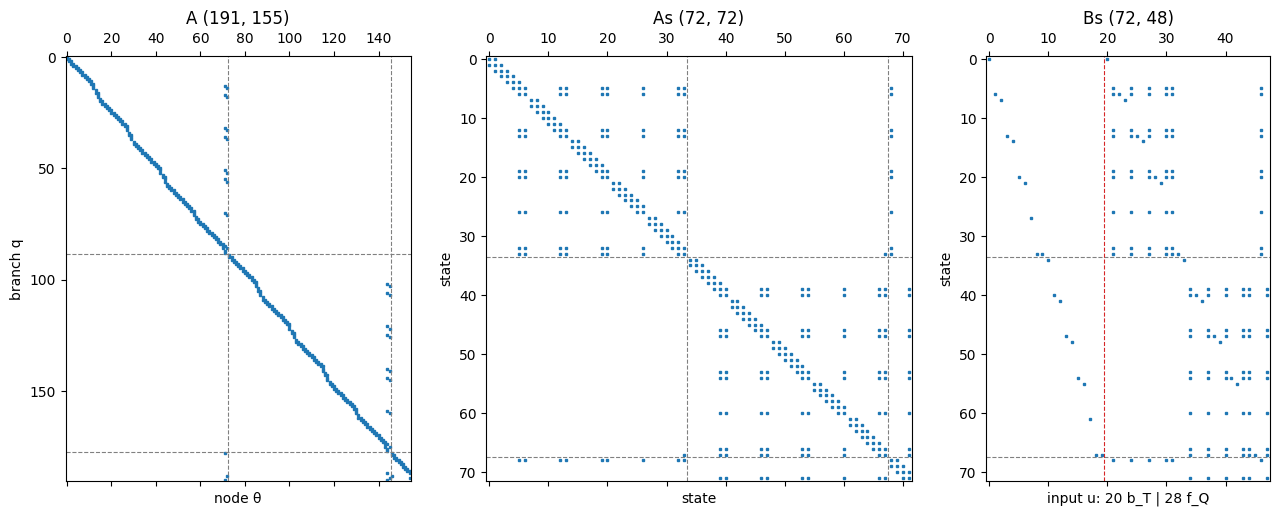

max |row sum of [As, Bs_T]| = 2.8e-17 1/s
case 1: test: time constants -1/λ of As from 515 s to 17.6 d, explicit Euler stable for Δt < 2/|λ|max = 1031 s
case 2: design heating: time constants -1/λ of As from 8 s to 7.9 d, explicit Euler stable for Δt < 2/|λ|max = 16 s


In [12]:
As, Bs, Cs, Ds = cases['case 2: design heating']['ss']
states = np.flatnonzero(np.diag(C))                 # nodes with capacity = states, in the order of the nodes
n_bT = int(b_ptr.sum())                             # number of temperature sources in u
fig, axs = plt.subplots(1, 3, figsize=(13, 5), gridspec_kw={'width_ratios': [155 / 191, 1, 48 / 72]})   # same height
for ax, M, title in zip(axs, (A, As, Bs), (f'A {A.shape}', f'As {As.shape}', f'Bs {Bs.shape}')):
    ax.spy(M, markersize=1.5)
    ax.set_title(title)
for n in (73, 146):                                 # zones in A: nodes (columns) and branches (rows)
    axs[0].axvline(n - 0.5, color='grey', ls='--', lw=0.8)
for k in (89, 178):
    axs[0].axhline(k - 0.5, color='grey', ls='--', lw=0.8)
for s in np.searchsorted(states, (73, 146)):        # zones in As and Bs: states
    for ax in axs[1:]:
        ax.axhline(s - 0.5, color='grey', ls='--', lw=0.8)
    axs[1].axvline(s - 0.5, color='grey', ls='--', lw=0.8)
axs[2].axvline(n_bT - 0.5, color='tab:red', ls='--', lw=0.8)
axs[0].set(xlabel='node θ', ylabel='branch q')
axs[1].set(xlabel='state', ylabel='state')
axs[2].set(xlabel=f'input u: {n_bT} b_T | {Bs.shape[1] - n_bT} f_Q', ylabel='state')
plt.tight_layout()
plt.show()

# uniform temperature, no flow-rate sources: steady state, so every row of [As, Bs_T] sums to zero
print(f'max |row sum of [As, Bs_T]| = {np.abs(As.sum(axis=1) + Bs[:, :n_bT].sum(axis=1)).max():.1e} 1/s')
for name in ('case 1: test', 'case 2: design heating'):
    lam = np.linalg.eigvals(cases[name]['ss'][0]).real
    print(f'{name}: time constants -1/λ of As from {-1 / lam.min():.0f} s to {-1 / lam.max() / 86400:.1f} d, '
          f'explicit Euler stable for Δt < 2/|λ|max = {2 / -lam.min():.0f} s')

Row of the air node $\theta_{71}$ (zone 1). Times $C_{air}$ the entries are conductances in W/K (energy
balance of the air); with the temperature sources the row sums to zero. $T_o$ acts directly only through
ventilation, internal gains enter with $B_s \cdot C_{air} = 1$. Of $\Phi_i$ absorbed on an inner surface only
0.04 to 0.5 reaches the air directly; the rest goes to the mesh behind and, radiatively, to the other elements.

In [13]:
def node_name(i):
    """Element and layer of node θi (numbering of Assignment 1)."""
    if i >= 146:                                                   # interior wall θ146 … θ154
        return f'interior wall, concrete {(i - 145) // 2}' if (i - 146) % 2 else f'interior wall θ{i}'
    z, k = divmod(i, 73)
    if k >= 71:
        return f'{("air", "star node")[k - 71]} zone {z + 1}'
    o = 'SN'[z]
    for e, layers, n in [(f'wall {o}', wall, 13), (f'window {o}', None, 2), ('wall E', wall, 13), ('window E', None, 2),
                         ('wall W', wall, 13), ('window W', None, 2), ('roof', roof, 13), ('floor', floor, 13)]:
        if k < n:
            break
        k -= n
    if layers is None:
        return f'{e} zone {z + 1}, {("glass", "inner surface")[k]}'
    mesh = {1: (0, 1), 3: (0, 2), 5: (1, 1), 7: (1, 2), 9: (1, 3), 11: (1, 4)}
    if k in mesh:
        j, m = mesh[k]
        return f'{e} zone {z + 1}, {layers[j][0].replace("_", " ")} {m}'
    return f'{e} zone {z + 1}, {("outer surface" if k == 0 else "inner surface" if k == 12 else f"θ{i}")}'


s_air = int(np.searchsorted(states, air1))          # state of the air node θ71
C_air = C[air1, air1]
row_As = pd.DataFrame({'node': [node_name(i) for i in states], 'As (1/s)': As[s_air],
                       'As · C_air (W/K)': As[s_air] * C_air},
                      index=[f'θ{i}' for i in states])
row_Bs = pd.DataFrame({'Bs': Bs[s_air], 'Bs · C_air': Bs[s_air] * C_air,
                       'unit': ['1/s | W/K'] * n_bT + ['K/J | –'] * (Bs.shape[1] - n_bT)}, index=u_names)
print(f'air node θ{air1} = state {s_air}, C_air = {C_air:.4g} J/K, time constant C_air / Σ G = '
      f'{-1 / As[s_air, s_air]:.0f} s')
print(f'non-zero: {np.count_nonzero(row_As["As (1/s)"])} of {As.shape[1]} in As, '
      f'{np.count_nonzero(row_Bs["Bs"])} of {Bs.shape[1]} in Bs')
print(f'Cs: one 1 per row at states {[int(np.flatnonzero(r)[0]) for r in Cs]} (air nodes θ{air1}, θ{air2}); '
      f'Ds = 0: {not Ds.any()}')
display(row_As[row_As['As (1/s)'] != 0].style.format({'As (1/s)': '{:.3e}', 'As · C_air (W/K)': '{:.1f}'}))
display(row_Bs[row_Bs['Bs'] != 0].style.format({'Bs': '{:.3e}', 'Bs · C_air': '{:.4g}'}))

air node θ71 = state 33, C_air = 8.1e+05 J/K, time constant C_air / Σ G = 8 s
non-zero: 11 of 72 in As, 9 of 48 in Bs
Cs: one 1 per row at states [33, 67] (air nodes θ71, θ144); Ds = 0: True


,node,As (1/s),As · C_air (W/K)
θ11,"wall S zone 1, concrete 4",1.696e-04,137.3
θ13,"window S zone 1, glass",6.091e-05,49.3
θ26,"wall E zone 1, concrete 4",4.239e-05,34.3
θ28,"window E zone 1, glass",1.523e-05,12.3
θ41,"wall W zone 1, concrete 4",4.239e-05,34.3
θ43,"window W zone 1, glass",1.523e-05,12.3
θ56,"roof zone 1, concrete 4",1.026e-03,831.1
θ69,"floor zone 1, concrete 4",1.089e-04,88.2
θ71,air zone 1,-1.254e-01,-101543.7
θ144,air zone 2,4.567e-06,3.7


,Bs,Bs · C_air,unit
b: q87 (T_o),6.184e-05,50.09,1/s | W/K
"b: q88 (T_sp,1)",1.235e-01,1e+05,1/s | W/K
f: θ12 (Φi),4.517e-08,0.03659,K/J | –
f: θ27 (Φi),4.517e-08,0.03659,K/J | –
f: θ42 (Φi),4.517e-08,0.03659,K/J | –
f: θ57 (Φi),6.940e-08,0.05621,K/J | –
f: θ70 (Φi),5.887e-07,0.4769,K/J | –
f: θ71 (Q̇occ + Q̇equip + Q̇light),1.235e-06,1,K/J | –
f: θ146 (Φi),5.544e-08,0.04491,K/J | –
